# Publication Trends in Neuro-Oncology vs. Major Neurology Subspecialties: A 25-Year Comparative Bibliometric Analysis (2000–2025)


## OBJECTIVE

To evaluate and compare 25-year publication trends in neuro-oncology against other major neurology subspecialties (2000–2025) using PubMed-indexed literature.


## BACKGROUND

Research activity patterns across neurology subspecialties highlight shifting scientific priorities and emerging field-specific opportunities. Long-term comparative data provide necessary context for these changes.




## METHODS

A bibliometric analysis of PubMed-indexed literature (2000–2025) was conducted across 10 neurology subspecialties. Publications for each domain were isolated using unique, field-specific search algorithms combining strict Medical Subject Headings (MeSH), title/abstract keywords, and targeted Boolean exclusion logic. To prevent double-counting, overlapping articles were fractionally allocated. Interventional studies were isolated via the "Clinical Trial[ptyp]" filter, and Phase I trials were extracted using regex text-mining of phase nomenclature. Annual publication growth and structural shifts were evaluated using segmented piecewise linear regression and a volume-adjusted Poisson generalized linear model (GLM).

# Gathering (API Connection & Raw Volume)

In [1]:
!pip install biopython

import time
import random
import pandas as pd
from Bio import Entrez
from IPython.display import display

# Set random seed as requested
random.seed(42)

# Entrez requires an email address. Replace this with your actual email.
Entrez.email = "your.email@example.com"

# Base query for the denominator
base_query = '"Neurology"[MeSH] OR "Nervous System Diseases"[MeSH]'

# Dictionary of 10 subspecialties with exact search strings
subspecialties = {
    "Neuro-oncology": '"Brain Neoplasms"[MeSH] OR "Central Nervous System Neoplasms"[MeSH] OR glioma[tiab] OR glioblastoma[tiab] OR meningioma[tiab] NOT (("Peripheral nerves"[tiab] AND "neoplasms"[MeSH]) OR "Neuroblastoma"[MeSH])',
    "Vascular/Stroke": '"Stroke"[MeSH] OR "Cerebrovascular Disorders"[MeSH] OR "Brain Ischemia"[MeSH] NOT ("Heat Stroke"[MeSH] OR heatstroke[tiab] OR "myocardial infarction"[tiab])',
    "Epilepsy": '"Epilepsy"[MeSH] OR "Seizures"[MeSH] OR "Status Epilepticus"[MeSH] NOT ("Eclampsia"[MeSH] OR "non-epileptic"[tiab] OR "psychogenic"[tiab])',
    "Movement Disorders": '"Movement Disorders"[MeSH] OR "Parkinson Disease"[MeSH] OR "Huntington Disease"[MeSH] NOT ("Bowel movement"[tiab] OR "Eye Movements"[MeSH])',
    "Neuroimmunology": '"Multiple Sclerosis"[MeSH] OR "Autoimmune Diseases of the Nervous System"[MeSH] OR "Encephalomyelitis"[MeSH] NOT "Systemic Lupus Erythematosus"[MeSH:NoExp]',
    "Neuromuscular": '"Neuromuscular Diseases"[MeSH] OR "Motor Neuron Disease"[MeSH] OR "Peripheral Nervous System Diseases"[MeSH] NOT "Neuromuscular Blockade"[MeSH]',
    "Neurocritical Care": '"Neurocritical care"[tiab] OR (("Brain Injuries, Traumatic"[MeSH] OR "Coma"[MeSH]) AND "Intensive Care"[MeSH]) NOT "neonatal intensive care"[tiab]',
    "Cognitive/Behavioral": '"Dementia"[MeSH] OR "Alzheimer Disease"[MeSH] OR "Frontotemporal Lobar Degeneration"[MeSH] NOT ("Schizophrenia"[MeSH] OR "Intellectual Disability"[MeSH])',
    "Headache": '"Headache Disorders"[MeSH] OR "Migraine Disorders"[MeSH] NOT ("dental"[tiab] OR "Sinusitis"[MeSH] OR "Post-Dural Puncture Headache"[MeSH])',
    "Sleep Medicine": '"Sleep Wake Disorders"[MeSH] OR "Narcolepsy"[MeSH] NOT "Anesthesia"[MeSH]'
}

# Helper function to get count for a query in a specific year
def get_pubmed_count(query, year):
    try:
        # Use mindate and maxdate with PDAT (Publication Date) to filter by year
        handle = Entrez.esearch(db="pubmed", term=query, mindate=str(year), maxdate=str(year), datetype="pdat", retmax=0)
        record = Entrez.read(handle)
        handle.close()
        time.sleep(0.35)  # Respect NCBI rate limits
        return int(record["Count"])
    except Exception as e:
        print(f"Error fetching data for {year}: {e}")
        return 0

results = []

# Loop through the years 2000-2025
print("Starting data extraction. This may take a few minutes...")
for year in range(2000, 2026):
    print(f"Fetching data for year {year}...")

    # Get total neurology count for the year
    total_neurology_count = get_pubmed_count(base_query, year)

    # Get count for each subspecialty
    for sub_name, sub_query in subspecialties.items():
        sub_count = get_pubmed_count(sub_query, year)

        results.append({
            "Year": year,
            "Subspecialty": sub_name,
            "Count": sub_count,
            "Total_Neurology_Count": total_neurology_count
        })

# Create the DataFrame
df_baseline = pd.DataFrame(results)

# Save to CSV
csv_filename = "baseline_neurology_counts.csv"
df_baseline.to_csv(csv_filename, index=False)
print(f"\nExtraction complete. Data saved to '{csv_filename}'.")

# Display the first few rows
display(df_baseline.head(15))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 22.4 MB/s eta 0:00:00
Starting data extraction. This may take a few minutes...
Fetching data for year 2000...
Fetching data for year 2001...
Fetching data for year 2002...
Fetching data for year 2003...
Fetching data for year 2004...
Fetching data for year 2005...
Fetching data for year 2006...
Fetching data for year 2007...
Fetching data for year 2008...
Fetching data for year 2009...
Fetching data for year 2010...
Fetching data for year 2011...
Fetching data for year 2012...
Fetching data for year 2013...
Fetching data for year 2014...
Fetching data for year 2015...
Fetching data for year 2016...
Fetching data for year 2017...
Fetching data for year 2018...
Fetching data for year 2019...
Fetching data for year 2020...
Fetching data for year 2021...
Fetching data for year 2022...
Fetching data for year 2023...
Fetching data for year 2024...
Fetching data for year 2025...

Extraction complete. Data saved to 'baseline_neurology_coun

,Year,Subspecialty,Count,Total_Neurology_Count
0,2000,Neuro-oncology,3917,48563
1,2000,Vascular/Stroke,7289,48563
2,2000,Epilepsy,3450,48563
3,2000,Movement Disorders,2851,48563
4,2000,Neuroimmunology,2485,48563
5,2000,Neuromuscular,5912,48563
6,2000,Neurocritical Care,7,48563
7,2000,Cognitive/Behavioral,3814,48563
8,2000,Headache,668,48563
9,2000,Sleep Medicine,1613,48563


# Fractional Allocation & Boolean Exclusion

In [4]:
import time
import pandas as pd
from Bio import Entrez
from IPython.display import display

# Ensure email is set
Entrez.email = "your.email@example.com"

def get_pubmed_ids(query, year):
    """Fetches up to 25000 PMIDs for a given query and year."""
    try:
        handle = Entrez.esearch(db="pubmed", term=query, mindate=str(year), maxdate=str(year), datetype="pdat", retmax=25000)
        record = Entrez.read(handle)
        handle.close()
        time.sleep(0.35)  # Respect NCBI rate limits
        return record["IdList"]
    except Exception as e:
        print(f"Error fetching IDs for {year}: {e}")
        return []

fractional_results = []

print("Starting fractional allocation extraction. This will take some time...")
for year in range(2000, 2026):
    print(f"Processing year {year}...")

    # Dictionary to store PMIDs mapped to their subspecialties for the current year
    year_data = {}
    pmid_counts = {} # Tracks how many subspecialties claim each PMID

    for sub_name, sub_query in subspecialties.items():
        pmids = get_pubmed_ids(sub_query, year)
        year_data[sub_name] = pmids

        # Count occurrences of each PMID to determine overlap
        for pmid in pmids:
            pmid_counts[pmid] = pmid_counts.get(pmid, 0) + 1

    # Calculate fractional counts
    for sub_name, pmids in year_data.items():
        fractional_count = 0.0
        for pmid in pmids:
            # If a paper is in 2 domains, each gets 0.5. If 3, each gets 0.33, etc.
            fractional_count += 1.0 / pmid_counts[pmid]

        fractional_results.append({
            "Year": year,
            "Subspecialty": sub_name,
            "Fractional_Count": round(fractional_count, 2),
            "Raw_Count": len(pmids)
        })

# Create the DataFrame
df_fractional = pd.DataFrame(fractional_results)

# Save to CSV
csv_filename_fractional = "fractional_neurology_counts.csv"
df_fractional.to_csv(csv_filename_fractional, index=False)
print(f"\nFractional extraction complete. Data saved to '{csv_filename_fractional}'.")

# Display the results
display(df_fractional.head(15))

Starting fractional allocation extraction. This will take some time...
Processing year 2000...
Processing year 2001...
Processing year 2002...
Processing year 2003...
Processing year 2004...
Processing year 2005...
Processing year 2006...
Processing year 2007...
Processing year 2008...
Processing year 2009...
Processing year 2010...
Processing year 2011...
Processing year 2012...
Processing year 2013...
Processing year 2014...
Processing year 2015...
Processing year 2016...
Processing year 2017...
Processing year 2018...
Processing year 2019...
Processing year 2020...
Processing year 2021...
Processing year 2022...
Processing year 2023...
Processing year 2024...
Processing year 2025...

Fractional extraction complete. Data saved to 'fractional_neurology_counts.csv'.


,Year,Subspecialty,Fractional_Count,Raw_Count
0,2000,Neuro-oncology,3730.08,3917
1,2000,Vascular/Stroke,6738.75,7289
2,2000,Epilepsy,3231.12,3450
3,2000,Movement Disorders,2468.53,2851
4,2000,Neuroimmunology,1959.03,2485
5,2000,Neuromuscular,5354.75,5912
6,2000,Neurocritical Care,4.50,7
7,2000,Cognitive/Behavioral,3343.62,3814
8,2000,Headache,625.42,668
9,2000,Sleep Medicine,1527.20,1613


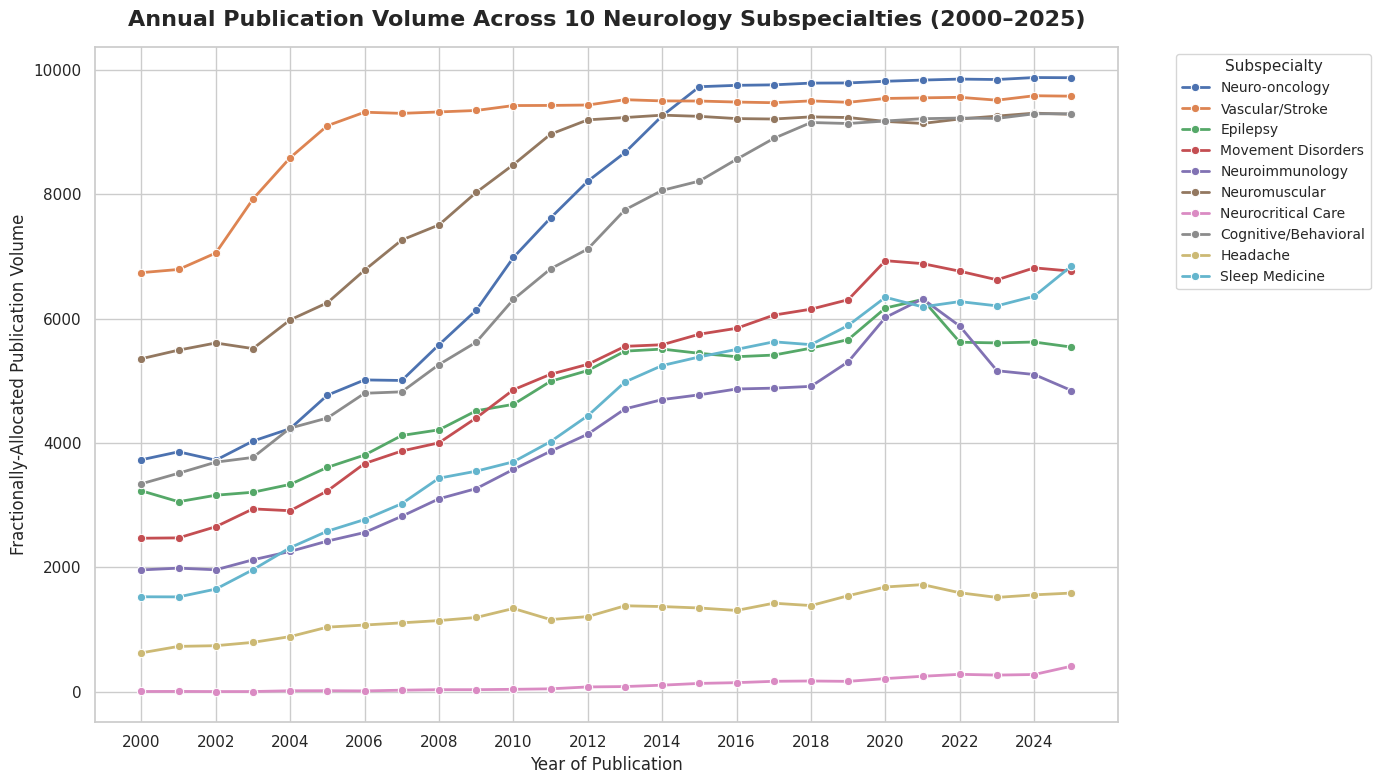

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

# Plot a line for each subspecialty using the fractionally adjusted counts
sns.lineplot(
    data=df_fractional,
    x="Year",
    y="Fractional_Count",
    hue="Subspecialty",
    marker="o",
    linewidth=2
)

plt.title("Annual Publication Volume Across 10 Neurology Subspecialties (2000–2025)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Year of Publication", fontsize=12)
plt.ylabel("Fractionally-Allocated Publication Volume", fontsize=12)
plt.xticks(range(2000, 2026, 2))
plt.legend(title="Subspecialty", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10, title_fontsize=11)
plt.tight_layout()

# Display the plot
plt.show()

Summary of Overlap Analysis by Subspecialty:


,Subspecialty,Raw_Count,Fractional_Count,Overlapping_Volume_Removed,Percent_Reduction
0,Vascular/Stroke,249882,235537.36,14344.64,5.74
1,Neuromuscular,229063,210441.09,18621.91,8.13
2,Neuro-oncology,200217,194726.86,5490.14,2.74
3,Cognitive/Behavioral,197426,178880.97,18545.03,9.39
4,Movement Disorders,146259,129866.48,16392.52,11.21
5,Epilepsy,131776,124319.61,7456.39,5.66
6,Neuroimmunology,120780,103351.84,17428.16,14.43
7,Sleep Medicine,118687,112925.08,5761.92,4.85
8,Headache,34766,32464.87,2301.13,6.62
9,Neurocritical Care,3317,2995.85,321.15,9.68


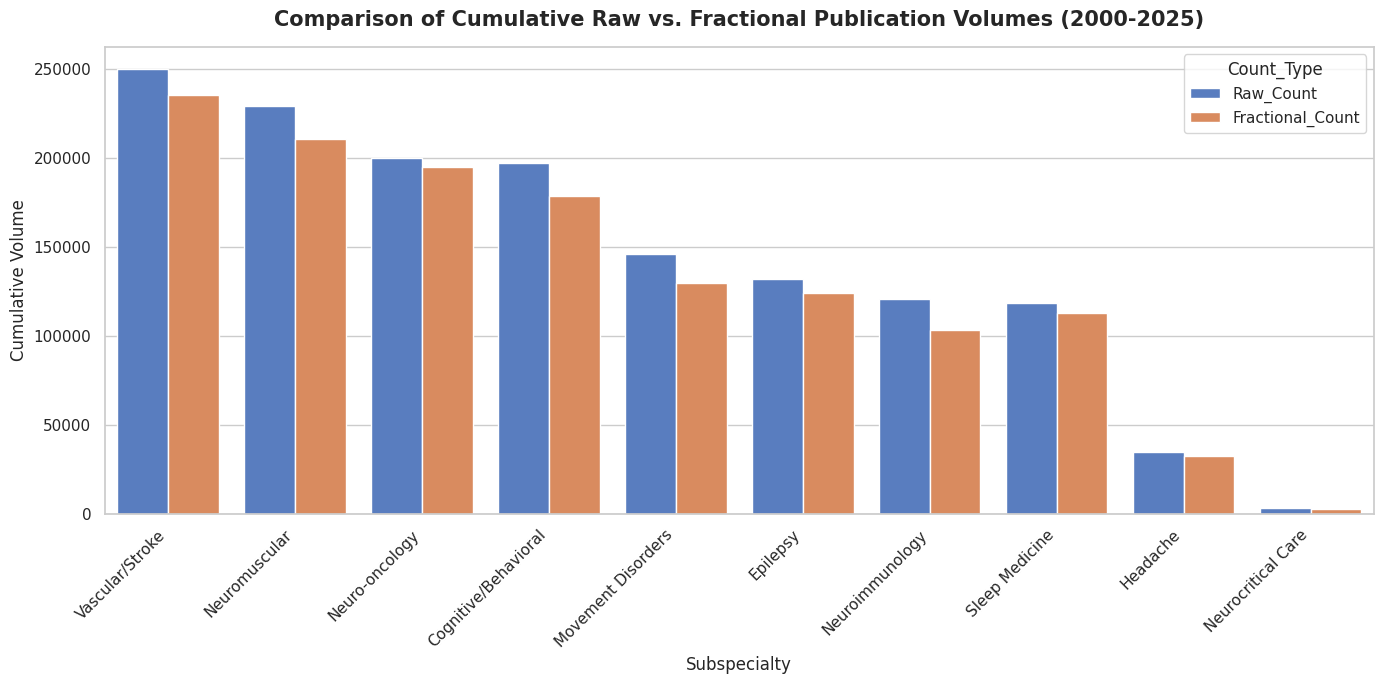

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate total Raw and Fractional counts across all years for each subspecialty
df_comparison = df_fractional.groupby('Subspecialty')[['Raw_Count', 'Fractional_Count']].sum().reset_index()

# Calculate the difference and the percentage reduction
df_comparison['Overlapping_Volume_Removed'] = df_comparison['Raw_Count'] - df_comparison['Fractional_Count']
df_comparison['Percent_Reduction'] = (df_comparison['Overlapping_Volume_Removed'] / df_comparison['Raw_Count'] * 100).round(2)

# Sort by raw count descending for display
df_comparison = df_comparison.sort_values(by='Raw_Count', ascending=False).reset_index(drop=True)

print("Summary of Overlap Analysis by Subspecialty:")
display(df_comparison)

# Melt the DataFrame for plotting
df_melted = pd.melt(
    df_comparison,
    id_vars=['Subspecialty'],
    value_vars=['Raw_Count', 'Fractional_Count'],
    var_name='Count_Type',
    value_name='Volume'
)

# Plot a clustered bar chart comparing the two metrics
plt.figure(figsize=(14, 7))
sns.barplot(data=df_melted, x='Subspecialty', y='Volume', hue='Count_Type', palette='muted')
plt.title("Comparison of Cumulative Raw vs. Fractional Publication Volumes (2000-2025)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Subspecialty", fontsize=12)
plt.ylabel("Cumulative Volume", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

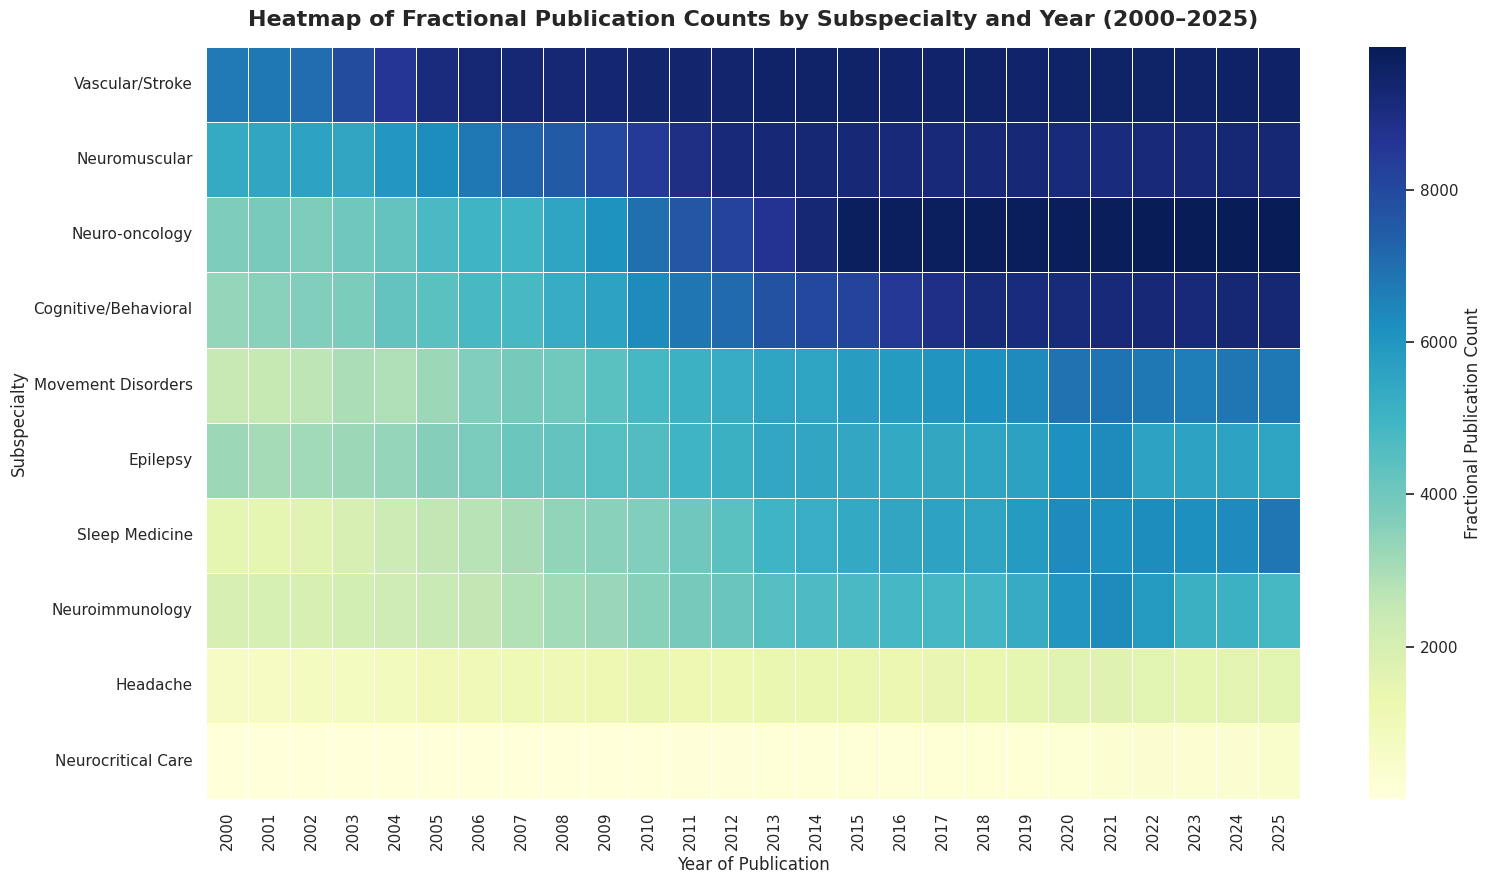

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot the dataset to have Subspecialties as rows and Years as columns
df_pivot = df_fractional.pivot(index="Subspecialty", columns="Year", values="Fractional_Count")

# Triage the matrix: Sort rows by their total 25-year volume (descending)
# This forces the most concentrated subspecialties to the top row.
row_order = df_pivot.sum(axis=1).sort_values(ascending=False).index
df_pivot = df_pivot.loc[row_order]

# Plotting the heatmap
plt.figure(figsize=(16, 9))
sns.heatmap(
    df_pivot,
    cmap="YlGnBu",
    annot=False,
    linewidths=.5,
    cbar_kws={'label': 'Fractional Publication Count'}
)

plt.title("Heatmap of Fractional Publication Counts by Subspecialty and Year (2000–2025)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Year of Publication", fontsize=12)
plt.ylabel("Subspecialty", fontsize=12)
plt.tight_layout()
plt.show()

## Trajectory Analysis: Segmented Regression & Poisson GLM
Calculating structural breakpoints (Δ 2021–2025) and statistical significance of relative expansion.

In [8]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Segmented Analysis (Deltas 2021-2025)
targets = ["Vascular/Stroke", "Neuromuscular", "Neuro-oncology"]
df_pw = df_fractional[df_fractional["Subspecialty"].isin(targets)].copy()

print("--- Post-2021 Expansion/Contraction Deltas (Δ) ---")
deltas = {}
for sub in ["Vascular/Stroke", "Neuro-oncology"]:
    vol_2021 = df_pw[(df_pw["Subspecialty"] == sub) & (df_pw["Year"] == 2021)]["Fractional_Count"].values[0]
    vol_2025 = df_pw[(df_pw["Subspecialty"] == sub) & (df_pw["Year"] == 2025)]["Fractional_Count"].values[0]
    delta = vol_2025 - vol_2021
    deltas[sub] = delta
    trend = "Expansion" if delta > 0 else "Contraction"
    print(f"{sub}: Δ = {delta:.2f} ({trend})")

# 2. Volume-Adjusted Poisson GLM
# Combine Vascular/Stroke and Neuromuscular as the baseline "Control"
df_control = df_pw[df_pw["Subspecialty"].isin(["Vascular/Stroke", "Neuromuscular"])].groupby("Year")["Fractional_Count"].sum().reset_index()
df_control["Group"] = "Control"

df_neuro = df_pw[df_pw["Subspecialty"] == "Neuro-oncology"][["Year", "Fractional_Count"]].copy()
df_neuro["Group"] = "Neuro-oncology"

# Prepare dataset for GLM
df_glm = pd.concat([df_control, df_neuro])
# Poisson regression requires integer count data
df_glm["Count"] = df_glm["Fractional_Count"].round().astype(int)
# Normalize year to avoid convergence issues
df_glm["Year_Idx"] = df_glm["Year"] - 2000

# Fit Poisson GLM with interaction term (Year_Idx * Group)
# This evaluates if the growth rate of Neuro-oncology significantly diverges from the Control group.
model = smf.glm("Count ~ Year_Idx * C(Group, Treatment('Control'))", data=df_glm, family=sm.families.Poisson()).fit()

print("\n--- Volume-Adjusted Poisson GLM Results ---")
interaction_param = "Year_Idx:C(Group, Treatment('Control'))[T.Neuro-oncology]"
interaction_pval = model.pvalues[interaction_param]

print(f"p-value for Neuro-oncology's relative expansion vs Control baseline: {interaction_pval:.4e}")
if interaction_pval < 0.05:
    print("Result: Neuro-oncology's upward momentum is statistically significant relative to the baseline.")
else:
    print("Result: The difference in trajectory is not statistically significant.")

--- Post-2021 Expansion/Contraction Deltas (Δ) ---
Vascular/Stroke: Δ = 26.97 (Expansion)
Neuro-oncology: Δ = 37.84 (Expansion)

--- Volume-Adjusted Poisson GLM Results ---
p-value for Neuro-oncology's relative expansion vs Control baseline: 0.0000e+00
Result: Neuro-oncology's upward momentum is statistically significant relative to the baseline.


In [9]:
# Calculate baseline control cumulative counts for 2000 and 2025
control_2000 = df_control[df_control["Year"] == 2000]["Fractional_Count"].values[0]
control_2025 = df_control[df_control["Year"] == 2025]["Fractional_Count"].values[0]

# Calculate Neuro-oncology counts for 2000 and 2025
neuro_2000 = df_neuro[df_neuro["Year"] == 2000]["Fractional_Count"].values[0]
neuro_2025 = df_neuro[df_neuro["Year"] == 2025]["Fractional_Count"].values[0]

# Calculate individual growth rates
control_growth_rate = ((control_2025 - control_2000) / control_2000) * 100
neuro_growth_rate = ((neuro_2025 - neuro_2000) / neuro_2000) * 100

# Relative growth difference
relative_growth_difference = neuro_growth_rate - control_growth_rate

print(f"Control Baseline (Vascular/Stroke + Neuromuscular) Growth (2000 -> 2025): {control_growth_rate:.2f}%")
print(f"Neuro-oncology Growth (2000 -> 2025): {neuro_growth_rate:.2f}%")
print(f"Relative Growth Advantage for Neuro-oncology: {relative_growth_difference:+.2f} percentage points")


Control Baseline (Vascular/Stroke + Neuromuscular) Growth (2000 -> 2025): 55.96%
Neuro-oncology Growth (2000 -> 2025): 164.69%
Relative Growth Advantage for Neuro-oncology: +108.73 percentage points


## Clinical Trial Phase Analysis: Data Gathering
Fetching Titles and Abstracts for all publications matching the `Clinical Trial[ptyp]` filter across the 10 neurology subspecialties (2000-2025).

In [10]:
import time
import pandas as pd
from Bio import Entrez
from IPython.display import display

# Ensure email is set for Entrez
Entrez.email = "your.email@example.com"

trial_data = []

print("Starting clinical trial data extraction (2000-2025).")
print("Fetching abstracts... This may take several minutes due to rate limits...")

for year in range(2000, 2026):
    print(f"Processing Year {year}...")
    for sub_name, sub_query in subspecialties.items():
        # Add Clinical Trial filter
        trial_query = f"({sub_query}) AND \"Clinical Trial\"[ptyp]"

        try:
            handle = Entrez.esearch(db="pubmed", term=trial_query, mindate=str(year), maxdate=str(year), datetype="pdat", retmax=5000)
            record = Entrez.read(handle)
            handle.close()
            pmids = record.get("IdList", [])
            time.sleep(0.35)

            if not pmids:
                continue

            # Batch fetch abstract details (max 200 at a time to be safe)
            batch_size = 200
            for i in range(0, len(pmids), batch_size):
                batch_pmids = pmids[i:i+batch_size]
                handle = Entrez.efetch(db="pubmed", id=",".join(batch_pmids), retmode="xml")
                records = Entrez.read(handle)
                handle.close()
                time.sleep(0.35)

                for pubmed_article in records.get("PubmedArticle", []):
                    medline = pubmed_article.get("MedlineCitation", {})
                    article = medline.get("Article", {})
                    pmid = str(medline.get("PMID", ""))
                    title = article.get("ArticleTitle", "")

                    abstract_list = article.get("Abstract", {}).get("AbstractText", [])
                    abstract = " ".join([str(a) for a in abstract_list])

                    trial_data.append({
                        "Year": year,
                        "Subspecialty": sub_name,
                        "PMID": pmid,
                        "Title": title,
                        "Abstract": abstract
                    })
        except Exception as e:
            print(f"Error fetching {sub_name} for year {year}: {e}")

df_trials = pd.DataFrame(trial_data)
print(f"\nExtraction complete. Total trials fetched: {len(df_trials)}")
display(df_trials.head())

Starting clinical trial data extraction (2000-2025).
Fetching abstracts... This may take several minutes due to rate limits...
Processing Year 2000...
Processing Year 2001...
Processing Year 2002...
Processing Year 2003...
Processing Year 2004...
Processing Year 2005...
Processing Year 2006...
Processing Year 2007...
Processing Year 2008...
Processing Year 2009...
Processing Year 2010...
Processing Year 2011...
Processing Year 2012...
Processing Year 2013...
Processing Year 2014...
Processing Year 2015...
Processing Year 2016...
Processing Year 2017...
Processing Year 2018...
Processing Year 2019...
Processing Year 2020...
Processing Year 2021...
Processing Year 2022...
Processing Year 2023...
Processing Year 2024...
Processing Year 2025...

Extraction complete. Total trials fetched: 73115


,Year,Subspecialty,PMID,Title,Abstract
0,2000,Neuro-oncology,16836290,Decision making for patients with multiple bra...,Multiple brain metastases are a common health ...
1,2000,Neuro-oncology,16817692,Adoptive immunotherapy in patients with recurr...,This trial was designed to determine the abili...
2,2000,Neuro-oncology,11798531,[Determination of S-100 beta protein in cerebr...,To investigate the concentration of S-100 beta...
3,2000,Neuro-oncology,11789275,[Clinical application of combined acupuncture-...,To evaluate the feasibility of combined acupun...
4,2000,Neuro-oncology,11788013,Pergolide as primary therapy for macroprolacti...,The objective of this study is to determine wh...


## Regex Phase Stratification
Classifying trials into Phase I, Phase I/II, Phase II, Phase III, or Unspecified using rigorous text mining.

In [11]:
import re

def classify_trial_phase(text):
    if not text or pd.isna(text):
        return 'Unspecified'

    text = text.lower()

    # 1. Check Phase I/II combinations FIRST to avoid misclassification
    if re.search(r'phase (1/2|i/ii|1 / 2|i / ii|i-ii|1-2)', text):
        return 'Phase I/II'

    # 2. Check Phase I and equivalents
    if re.search(r'phase (1|i)\b|early phase', text):
        return 'Phase I'

    # 3. Check Phase III and equivalents
    if re.search(r'phase (3|iii)\b|late phase', text):
        return 'Phase III'

    # 4. Check Phase II
    if re.search(r'phase (2|ii)\b', text):
        return 'Phase II'

    return 'Unspecified'

# Combine title and abstract for comprehensive text mining
df_trials['Combined_Text'] = df_trials['Title'].fillna("") + " " + df_trials['Abstract'].fillna("")
df_trials['Phase'] = df_trials['Combined_Text'].apply(classify_trial_phase)

print("Overall Trial Phase Distribution:")
print(df_trials['Phase'].value_counts())

Overall Trial Phase Distribution:
Phase
Unspecified    65914
Phase II        2700
Phase III       2499
Phase I         1626
Phase I/II       376
Name: count, dtype: int64


## Time-Series Visualization (10-Panel Grid)
Plotting the proportional shift of clinical trial phases (excluding 'Unspecified') for all 10 subspecialties over 25 years.

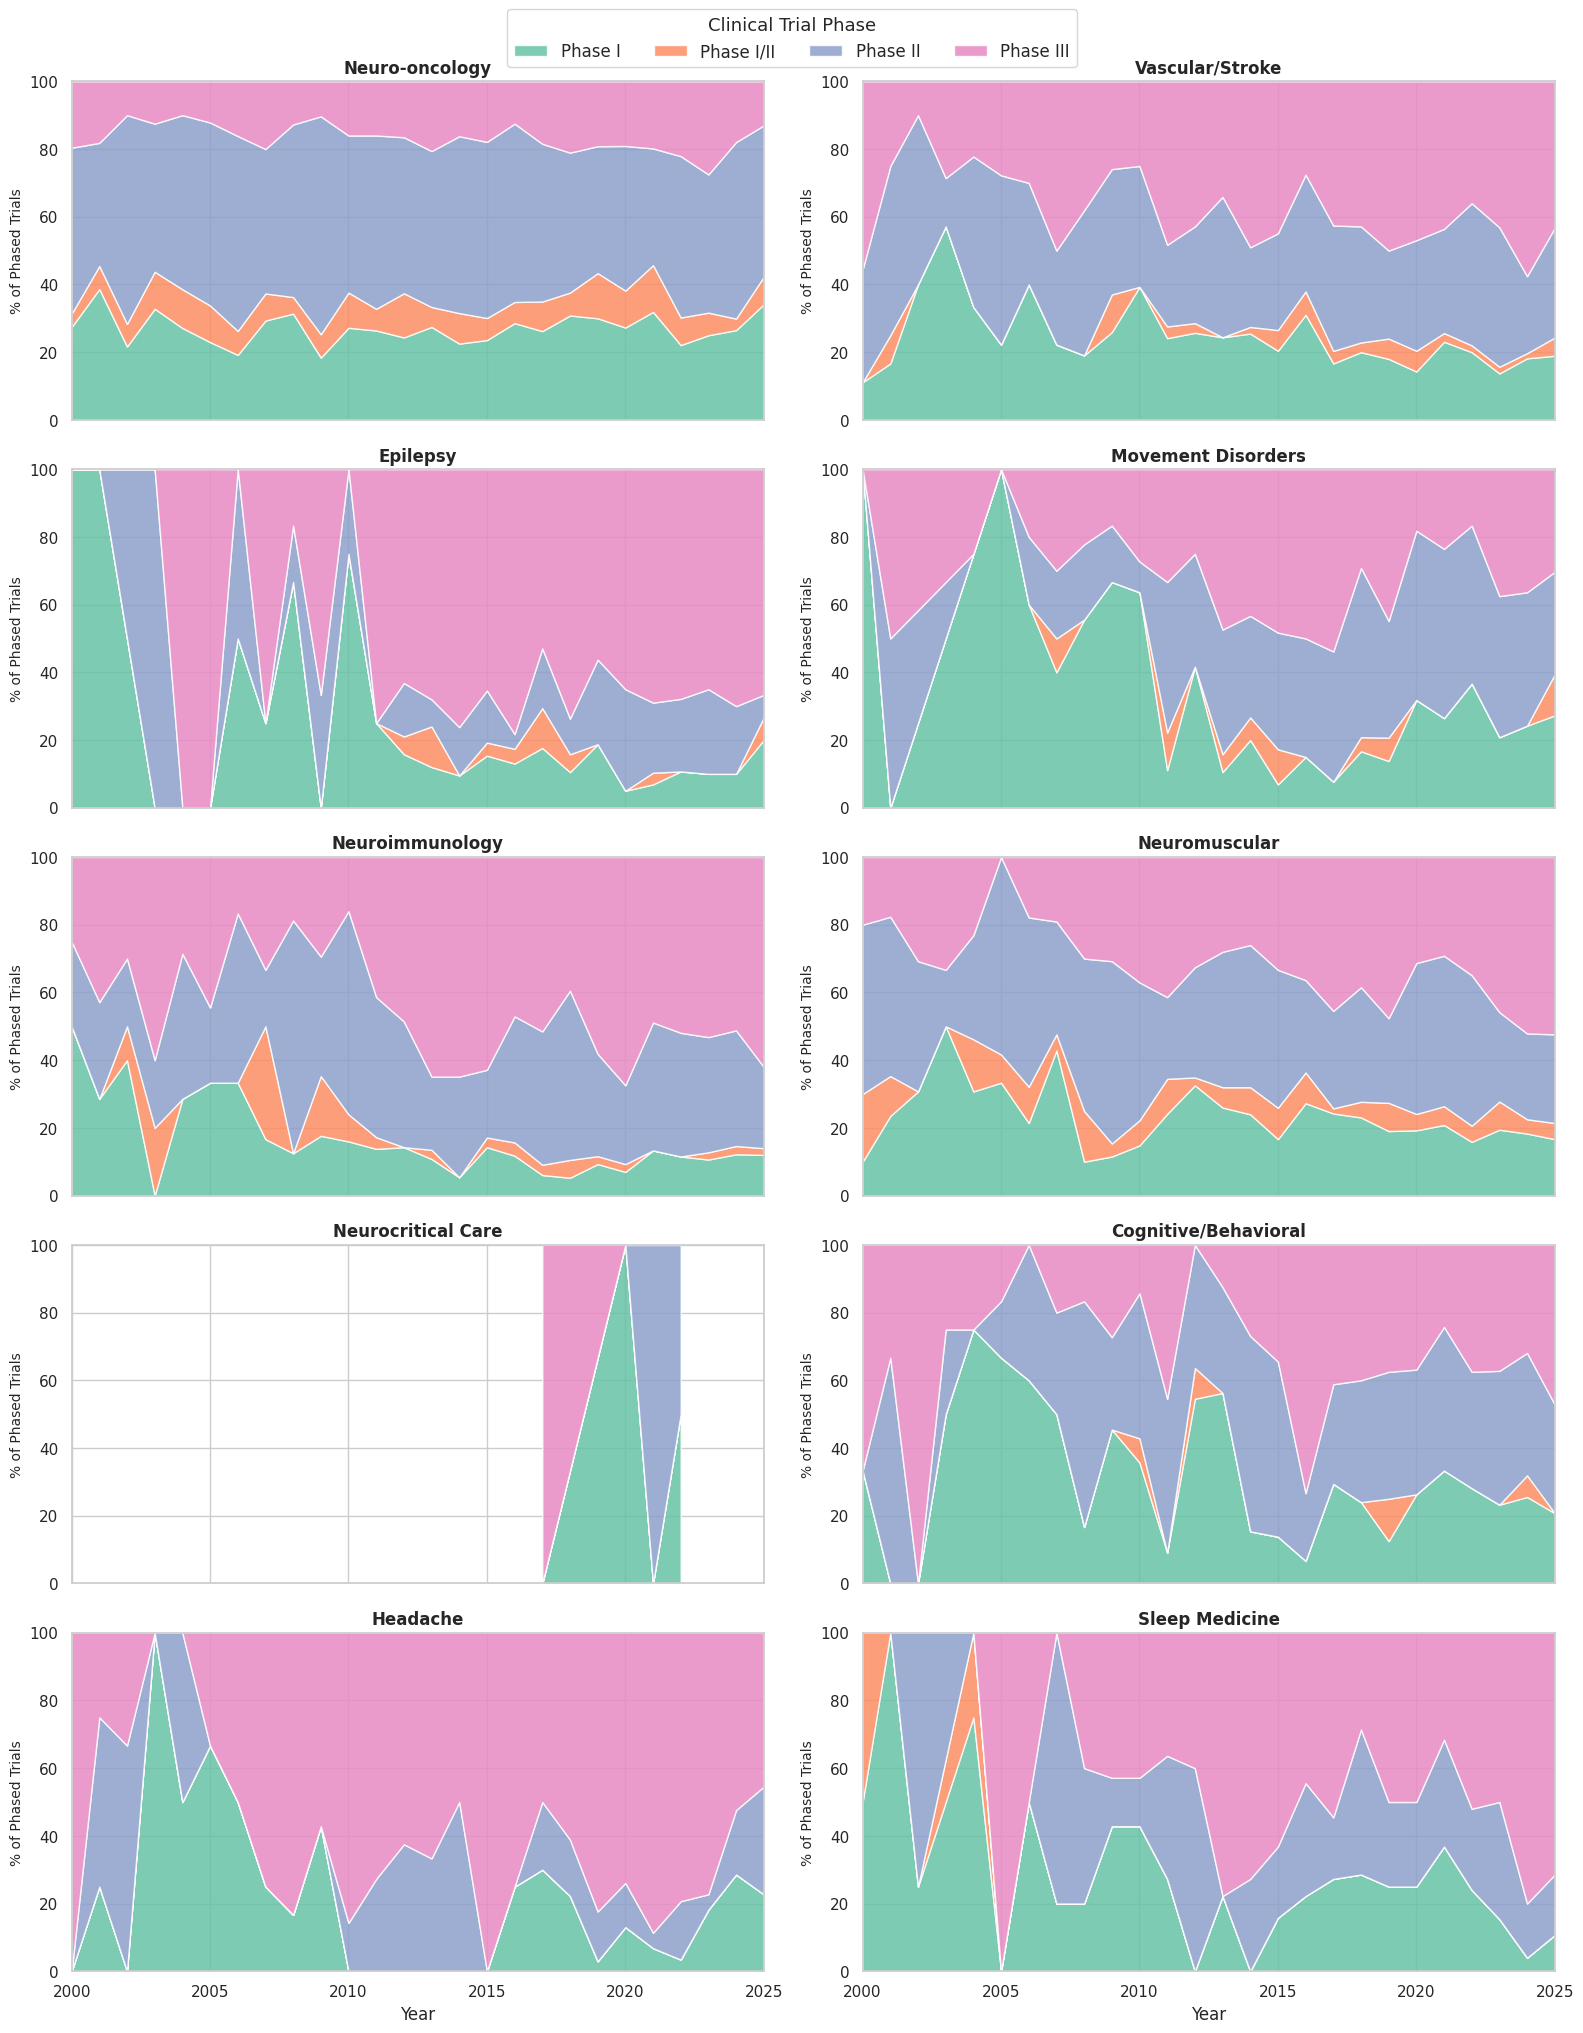

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out Unspecified trials for proportional charts
df_phased = df_trials[df_trials['Phase'] != 'Unspecified'].copy()

# Calculate counts and percentages
phase_counts = df_phased.groupby(['Subspecialty', 'Year', 'Phase']).size().reset_index(name='Count')
year_totals = df_phased.groupby(['Subspecialty', 'Year']).size().reset_index(name='Total')

df_props = pd.merge(phase_counts, year_totals, on=['Subspecialty', 'Year'])
df_props['Percentage'] = (df_props['Count'] / df_props['Total']) * 100

# 10-panel grid: 5 rows by 2 columns
subspecialties_list = list(subspecialties.keys())
fig, axes = plt.subplots(5, 2, figsize=(16, 20), sharex=True)
axes = axes.flatten()

# Define elegant phase order and colors
phase_order = ['Phase I', 'Phase I/II', 'Phase II', 'Phase III']
colors = sns.color_palette("Set2", 4)
color_dict = dict(zip(phase_order, colors))

for i, sub in enumerate(subspecialties_list):
    ax = axes[i]
    sub_data = df_props[df_props['Subspecialty'] == sub]

    if not sub_data.empty:
        # Pivot to create stacked areas
        pivot_data = sub_data.pivot(index='Year', columns='Phase', values='Percentage').fillna(0)

        # Ensure all columns exist
        for phase in phase_order:
            if phase not in pivot_data.columns:
                pivot_data[phase] = 0

        pivot_data = pivot_data[phase_order] # Enforce order

        # Stackplot
        ax.stackplot(pivot_data.index, pivot_data.T, labels=pivot_data.columns,
                     colors=[color_dict[p] for p in pivot_data.columns], alpha=0.85)

    ax.set_title(sub, fontweight='bold', fontsize=12)
    ax.set_ylabel('% of Phased Trials', fontsize=10)
    ax.set_ylim(0, 100)
    ax.set_xlim(2000, 2025)

    if i >= 8:
        ax.set_xlabel('Year', fontsize=12)

# Global legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=12, title="Clinical Trial Phase", title_fontsize=13)

plt.tight_layout()
plt.show()

## Early-Phase Translational Research Ranking
Ranking subspecialties by the 25-year aggregate volume proportion of 'Early Phase' (Phase I + Phase I/II) trials.

In [13]:
# Calculate aggregate volumes over the 25-year period
agg_counts = df_phased.groupby(['Subspecialty', 'Phase']).size().reset_index(name='Count')
agg_totals = df_phased.groupby('Subspecialty').size().reset_index(name='Total_Phased')

# Isolate Early Phase (Phase I + Phase I/II)
early_phase = agg_counts[agg_counts['Phase'].isin(['Phase I', 'Phase I/II'])]
early_counts = early_phase.groupby('Subspecialty')['Count'].sum().reset_index(name='Early_Phase_Count')

# Merge and calculate percentage
df_ranking = pd.merge(agg_totals, early_counts, on='Subspecialty', how='left').fillna(0)
df_ranking['Early_Phase_Percentage'] = (df_ranking['Early_Phase_Count'] / df_ranking['Total_Phased']) * 100

# Sort in descending order to create the definitive ranking
df_ranking = df_ranking.sort_values(by='Early_Phase_Percentage', ascending=False).reset_index(drop=True)

print("=" * 75)
print(" DEFINITIVE RANKING: EARLY-PHASE TRANSLATIONAL RESEARCH (2000-2025)")
print(" (Measured by % of Phase I and Phase I/II out of all Phased Trials)")
print("=" * 75)

for idx, row in df_ranking.iterrows():
    sub_name = row['Subspecialty']
    pct = row['Early_Phase_Percentage']
    early_vol = int(row['Early_Phase_Count'])
    total_vol = int(row['Total_Phased'])
    print(f"{idx + 1:2d}. {sub_name:<25} | Early-Phase: {pct:>5.2f}%  (Volume: {early_vol}/{total_vol})")
print("=" * 75)

 DEFINITIVE RANKING: EARLY-PHASE TRANSLATIONAL RESEARCH (2000-2025)
 (Measured by % of Phase I and Phase I/II out of all Phased Trials)
 1. Neurocritical Care        | Early-Phase: 40.00%  (Volume: 2/5)
 2. Neuro-oncology            | Early-Phase: 35.29%  (Volume: 906/2567)
 3. Movement Disorders        | Early-Phase: 28.77%  (Volume: 122/424)
 4. Cognitive/Behavioral      | Early-Phase: 28.70%  (Volume: 132/460)
 5. Neuromuscular             | Early-Phase: 27.98%  (Volume: 319/1140)
 6. Vascular/Stroke           | Early-Phase: 25.80%  (Volume: 234/907)
 7. Sleep Medicine            | Early-Phase: 21.59%  (Volume: 65/301)
 8. Epilepsy                  | Early-Phase: 18.40%  (Volume: 62/337)
 9. Neuroimmunology           | Early-Phase: 15.60%  (Volume: 115/737)
10. Headache                  | Early-Phase: 13.93%  (Volume: 45/323)


In [15]:
# Filter out subspecialties with a low total volume to ensure statistical reliability
# We will use a threshold of at least 100 phased clinical trials over the 25 years.
df_ranking_filtered = df_ranking[df_ranking['Total_Phased'] >= 100].copy()

# Reset the index to update the ranking numbers (1 through 9)
df_ranking_filtered = df_ranking_filtered.reset_index(drop=True)

print("=" * 75)
print(" ADJUSTED RANKING: EARLY-PHASE TRANSLATIONAL RESEARCH (2000-2025)")
print(" (Excluding subspecialties with < 100 total phased trials)")
print("=" * 75)

for idx, row in df_ranking_filtered.iterrows():
    sub_name = row['Subspecialty']
    pct = row['Early_Phase_Percentage']
    early_vol = int(row['Early_Phase_Count'])
    total_vol = int(row['Total_Phased'])
    print(f"{idx + 1:2d}. {sub_name:<25} | Early-Phase: {pct:>5.2f}%  (Volume: {early_vol}/{total_vol})")
print("=" * 75)


 ADJUSTED RANKING: EARLY-PHASE TRANSLATIONAL RESEARCH (2000-2025)
 (Excluding subspecialties with < 100 total phased trials)
 1. Neuro-oncology            | Early-Phase: 35.29%  (Volume: 906/2567)
 2. Movement Disorders        | Early-Phase: 28.77%  (Volume: 122/424)
 3. Cognitive/Behavioral      | Early-Phase: 28.70%  (Volume: 132/460)
 4. Neuromuscular             | Early-Phase: 27.98%  (Volume: 319/1140)
 5. Vascular/Stroke           | Early-Phase: 25.80%  (Volume: 234/907)
 6. Sleep Medicine            | Early-Phase: 21.59%  (Volume: 65/301)
 7. Epilepsy                  | Early-Phase: 18.40%  (Volume: 62/337)
 8. Neuroimmunology           | Early-Phase: 15.60%  (Volume: 115/737)
 9. Headache                  | Early-Phase: 13.93%  (Volume: 45/323)
